# 02 – Target analysis (task A2)
Before any modeling we study the label `defaulted` (1 = charged off or default,
0 = fully paid): the overall default rate and class balance, how the rate varies by
issue month and by term, and how removing loans still in progress biases recent and
60-month loans. Data: the audited training files (30,000 loans, 2013–2015).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

train = pd.read_parquet(Path("../data/interim/train_audited.parquet"))

n, rate = len(train), train["defaulted"].mean()
print(f"loans: {n:,} | defaults: {int(train['defaulted'].sum()):,} | default rate: {rate:.1%}")
print(f"class balance: {1 - rate:.1%} fully paid vs {rate:.1%} defaulted (about 1 in {round(1 / rate)})")

Matplotlib is building the font cache; this may take a moment.


loans: 30,000 | defaults: 5,617 | default rate: 18.7%
class balance: 81.3% fully paid vs 18.7% defaulted (about 1 in 5)


In [2]:
train["issue_year"] = train["issue_dt"].dt.year

by_term = train.groupby("term_months")["defaulted"].agg(loans="count", default_rate="mean")
by_year_term = train.pivot_table(index="issue_year", columns="term_months",
                                 values="defaulted", aggfunc=["count", "mean"])
display(by_term.round(3))
display(by_year_term.round(3))

,loans,default_rate
term_months,,
36,22328,0.140
60,7672,0.323


count         mean       
term_months     36    60     36     60
issue_year                            
2013          3971  1378  0.127  0.252
2014          6574  2450  0.135  0.300
2015         11783  3844  0.148  0.364

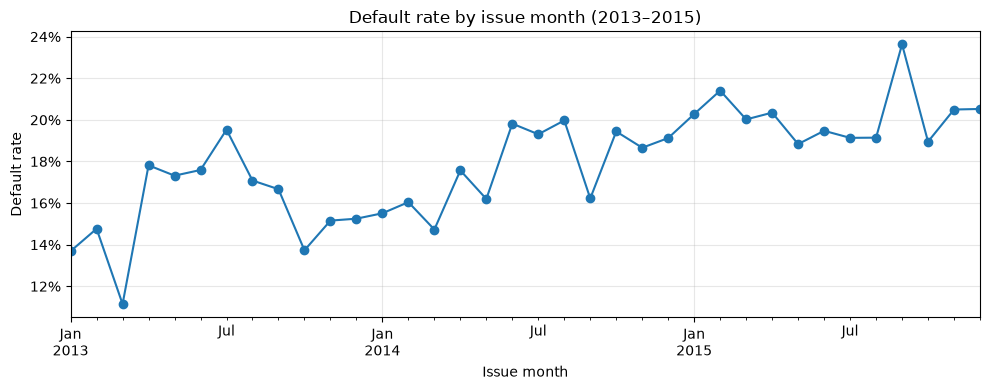

In [5]:
monthly = train.groupby(train["issue_dt"].dt.to_period("M"))["defaulted"].mean()

fig, ax = plt.subplots(figsize=(10, 4))
monthly.plot(ax=ax, marker="o")
ax.set_title("Default rate by issue month (2013–2015)")
ax.set_xlabel("Issue month")
ax.set_ylabel("Default rate")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
ax.grid(alpha=0.3)
plt.tight_layout()
fig.savefig("../reports/default_rate_by_month.png", dpi=150, bbox_inches="tight")
plt.show()

**Results.** The default rate is 18.7% (about 1 in 5), so accuracy is a misleading metric.
60-month loans default far more than 36-month loans (32.3% vs 14.0%). The 36-month rate
rises only slightly over time (12.7% → 14.8%), while the 60-month rate rises sharply
(25.2% → 36.4%). This pattern matches the bias created by removing loans still in
progress at the March 2019 snapshot: 60-month loans issued in 2015 were scheduled to run
until 2020, so the ones that remain are mostly those that ended early, by default or early
repayment, inflating their default rate. 2014 60-month loans are partly affected; 2013 and
36-month loans hardly at all. The 2015 validation set therefore overstates 60-month risk,
and apparent trends over time are partly an artifact.

### Measuring the in-progress bias
A loan's scheduled end is its issue date plus its term. Loans scheduled to end after the
March 2019 snapshot should still have been running; because only finished loans were
kept, any such loan in the data must have ended early, by default or early repayment.
We measure the share of these loans by year and term, and compare their default rate
with loans of the same term that were scheduled to end before the snapshot.

In [4]:
SNAPSHOT = pd.Timestamp("2019-03-01")

train["scheduled_end"] = train.apply(
    lambda r: r["issue_dt"] + pd.DateOffset(months=int(r["term_months"])), axis=1)
train["ended_early_only"] = train["scheduled_end"] > SNAPSHOT

print("share of loans that can only be here because they ended early:")
display(train.pivot_table(index="issue_year", columns="term_months",
                          values="ended_early_only", aggfunc="mean").round(2))

print("default rate, scheduled to end before vs after the snapshot:")
display(train.groupby(["term_months", "ended_early_only"])["defaulted"]
        .agg(loans="count", default_rate="mean").round(3))

share of loans that can only be here because they ended early:


term_months,36,60
issue_year,,
2013,0.0,0.00
2014,0.0,0.78
2015,0.0,1.00


default rate, scheduled to end before vs after the snapshot:


loans  default_rate
term_months ended_early_only                     
36          False             22328         0.140
60          False              1912         0.247
            True               5760         0.349

**Result: the bias is confirmed.** No 36-month loan and no 2013 60-month loan was
scheduled to run past March 2019, but 78% of 2014 and 100% of 2015 60-month loans were,
so those remain in the data only because they ended early. Among 60-month loans, the
default rate is 24.7% for loans scheduled to finish before the snapshot (unaffected) and
34.9% for those that could only have ended early: an inflation of about 10 points, most of
it artificial, since 36-month loans rose only ~2 points over the same period.
Consequences: metrics on the 2015 validation set are reported separately by term; the
model may overestimate 60-month risk; trends over time are partly an artifact. A survival
model using in-progress loans would remove this bias (future work).

## A2 summary
- Default rate 18.7% (5,617 of 30,000), about 1 in 5: imbalanced enough that accuracy is
  misleading; AUC, KS and calibration are used instead.
- 60-month loans default far more often than 36-month loans (32.3% vs 14.0%).
- Removing in-progress loans inflates the default rate of 2014–2015 60-month loans by
  about 10 points (24.7% unbiased vs 34.9% biased), so the 2015 validation set overstates
  60-month risk and time trends are partly artificial.